# Military vs. Civilian Aircraft Classification

Classifying images into **3 classes** with a CNN:

| Class | What it is |
|---|---|
| `military` | military aircraft (fighters, bombers, transports, helicopters, UAVs) |
| `civilian` | commercial airliners |
| `neither`  | birds and drones in the sky (no aircraft) |

**Data:** [Ahnuf/Military_Aircraft_Detection_Classification_Image_Dataset](https://huggingface.co/datasets/Ahnuf/Military_Aircraft_Detection_Classification_Image_Dataset) on Hugging Face.

**Steps in this notebook:**
1. Imports and settings
2. Download the dataset (only if it isn't downloaded yet)
3. Make a small subset of the images (`make_subset.py`)
4. Preprocess the subset: crop the watermark + resize (`preprocess.py`)
5. Check the result: image counts and sample images
6. Load the data into PyTorch batches: tensors, normalization, augmentation, DataLoaders
7. Build the CNN: the model's layers (not trained yet)
8. Train the CNN (or load it, if it was already trained with the same settings)

## 1. Imports and settings

In [33]:
# --- Standard Python libraries ---
import hashlib   # for turning the training settings into a short code (step 8)
import json      # for saving/loading the mean/std file (step 6)
import os        # for working with files and folders
import random    # for picking random sample images to show
import shutil    # for deleting an unfinished training run folder (step 8)
import time      # for timing each training epoch (step 8)
import zipfile   # for unzipping the downloaded dataset

# --- Installed libraries (see requirements.txt) ---
from huggingface_hub import hf_hub_download  # downloads files from Hugging Face
from PIL import Image                        # opens images
import matplotlib.pyplot as plt              # shows images in the notebook
import torch                                 # tensors (arrays of numbers) for the CNN
import torch.nn as nn                        # CNN building blocks: layers, loss functions
from torch.utils.data import DataLoader, Subset  # batches; Subset = a part of a dataset (step 8)
from torchvision import datasets, transforms # image folders -> datasets; resize/normalize/augment

# --- Our own scripts (in this same folder) ---
# Their settings (subset size, image size, ...) are at the top of each file.
# NOTE: if you edit those settings, restart the notebook kernel
#       so the new values are loaded.
import make_subset
import preprocess

# --- Settings for this notebook ---

# The Hugging Face dataset we download from
HF_REPO = "Ahnuf/Military_Aircraft_Detection_Classification_Image_Dataset"

# The zip file inside that dataset
ZIP_NAME = "dataset.zip"

# Folder where the zip file is downloaded to
DOWNLOAD_DIR = "data/raw"
ZIP_PATH = os.path.join(DOWNLOAD_DIR, ZIP_NAME)  # -> data/raw/dataset.zip

# Folder where the zip file is unzipped to.
# We take it from make_subset.py so both always use the same folder.
RAW_DIR = make_subset.RAW_DIR  # -> data/raw/dataset

# The 3 splits inside the dataset
SPLITS = ["train", "val", "test"]

## 2. Download the dataset (only if needed)

This cell checks three cases, in order:
1. **Already unzipped**: `data/raw/dataset/train`, `val` and `test` all exist, so nothing to do.
2. **Downloaded but not unzipped**: `data/raw/dataset.zip` exists, so just unzip it.
3. **Nothing yet**: download `dataset.zip` (about 2.9 GB) from Hugging Face, then unzip it.

The zip file is kept after unzipping.

In [34]:
# Check if every split folder (train, val, test) already exists
already_unzipped = all(os.path.isdir(os.path.join(RAW_DIR, split)) for split in SPLITS)

if already_unzipped:
    # Case 1: nothing to do
    print(f"Dataset already downloaded and unzipped in {RAW_DIR}")

else:
    # Case 3: the zip isn't here yet -> download it first
    if not os.path.exists(ZIP_PATH):
        print("Downloading dataset.zip (about 2.9 GB) - this can take a while...")
        hf_hub_download(
            repo_id=HF_REPO,          # which dataset
            filename=ZIP_NAME,        # which file in it
            repo_type="dataset",      # it's a dataset, not a model
            local_dir=DOWNLOAD_DIR,   # save it to data/raw/
        )
        print(f"Downloaded to {ZIP_PATH}")

    # Case 2 (and the end of case 3): unzip it
    print(f"Unzipping {ZIP_PATH} into {RAW_DIR} ...")
    with zipfile.ZipFile(ZIP_PATH) as zip_file:
        zip_file.extractall(RAW_DIR)
    print("Done unzipping.")

# Show how many files are in each split (images + their .txt label files)
for split in SPLITS:
    num_files = len(os.listdir(os.path.join(RAW_DIR, split)))
    print(f"  {split:5}: {num_files} files")

Dataset already downloaded and unzipped in data/raw/dataset
  train: 42684 files
  val  : 5282 files
  test : 5290 files


## 3. Make the subset

Runs `make_subset.py`. It picks a random, balanced set of images
(the number is set by `TOTAL` at the top of `make_subset.py`)
and saves the list as a CSV file in `data/subsets/`.

If a subset with the same settings already exists, it is reused instead of making a new one.

In [35]:
# Make the subset (or reuse it) and get the path to its CSV file
subset_csv = make_subset.make_subset()

print("Subset CSV:", subset_csv)

Subset already exists: data/subsets/subset_4450_b187ce.csv
Subset CSV: data/subsets/subset_4450_b187ce.csv


## 4. Preprocess the images

Runs `preprocess.py` on the subset from step 3. For every image it:
1. crops off the bottom strip (removes the watermark),
2. resizes it (224 x 224 by default),
3. saves it into `data/processed/<subset name>/<split>/<class>/`.

If this subset was already processed, it is skipped.

In [36]:
# Preprocess the images listed in the subset CSV (or skip if already done)
# and get the folder where the processed images are saved
processed_dir = preprocess.preprocess(subset_csv)

print("Processed images folder:", processed_dir)

Already processed: data/processed/subset_4450_b187ce
Processed images folder: data/processed/subset_4450_b187ce


## 5. Check the result

First, count how many images ended up in each split and class.
Then show a few random training images from each class, to check by eye that
the labels are right and the watermark strip is gone.

In [37]:
# ======================================================================
# CHECK ONLY - not needed for training.
# Lets you check step 4's result by eye.
# (It also defines CLASSES, which one print in 6.4 uses.)
# ======================================================================

# The 3 class names, in the same order as the folders
CLASSES = ["military", "civilian", "neither"]

# Count the images in every split/class folder
for split in SPLITS:
    for label in CLASSES:
        folder = os.path.join(processed_dir, split, label)
        num_images = len(os.listdir(folder))
        print(f"{split:5} {label:9} {num_images:5} images")

train military   1472 images
train civilian   1472 images
train neither     616 images
val   military    184 images
val   civilian    184 images
val   neither      77 images
test  military    184 images
test  civilian    184 images
test  neither      77 images


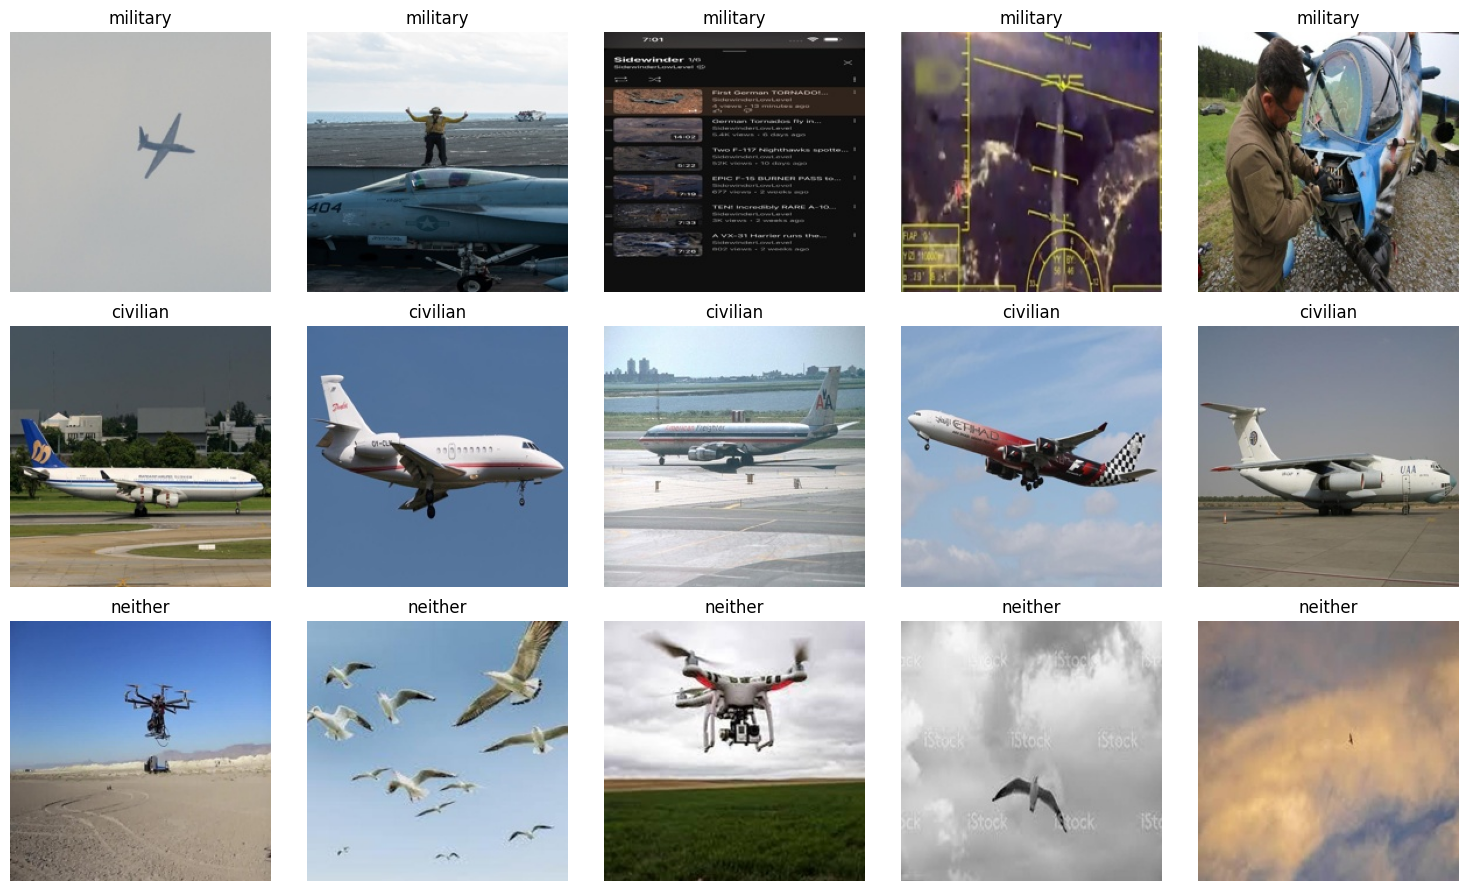

In [38]:
# ======================================================================
# CHECK ONLY - not needed for training.
# Lets you check step 4's result by eye. Safe to skip.
# ======================================================================

# How many sample images to show for each class
NUM_SAMPLES = 5

# Fixed seed so the same sample images are shown every time
rng = random.Random(0)

# Make a grid of pictures: one row per class, NUM_SAMPLES pictures per row
fig, axes = plt.subplots(len(CLASSES), NUM_SAMPLES, figsize=(3 * NUM_SAMPLES, 3 * len(CLASSES)))

for row, label in enumerate(CLASSES):
    # All training images of this class
    folder = os.path.join(processed_dir, "train", label)
    filenames = sorted(os.listdir(folder))

    # Pick a few at random
    picked = rng.sample(filenames, NUM_SAMPLES)

    for col, filename in enumerate(picked):
        img = Image.open(os.path.join(folder, filename))
        ax = axes[row][col]
        ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")  # hide the x/y axis numbers

plt.tight_layout()
plt.show()

## 6. Load the data (PyTorch DataLoaders)

The CNN can't read JPG files. It needs **tensors** (arrays of numbers) delivered in **batches**.
This section builds the "pipe" from the processed folders (step 4) to the model:

```
JPG on disk -> open -> resize -> (random changes, train only) -> tensor -> normalize -> batch of 32 -> CNN
```

It is split into small parts, each showing what happens to real images:

- **6.1** One image's journey: JPG -> resize -> tensor
- **6.2** Normalization: the mean and std
- **6.3** Augmentation: random changes for training images only
- **6.4** Labels from folder names (`ImageFolder`) and the class order
- **6.5** Batches (`DataLoader`) and why training images are shuffled
- **6.6** Why val/test are NOT shuffled and NOT augmented
- **6.7** Summary checklist

The settings for this section are in the next cell. After changing one, re-run section 6 from that cell down.

In [39]:
# --- Settings for loading the data ---

# Size (height = width) of the images the CNN sees, in pixels.
# The files on disk stay 224 x 224 (from step 4). They are only shrunk in memory
# while loading. 128 trains about 3x faster than 224. Set to 224 to use the full size.
IMAGE_SIZE = 128

# How many images are grouped into one batch (the model does one weight update per batch)
BATCH_SIZE = 32

# How many helper processes load images in parallel.
# Must stay 0 here: on a Mac, helper processes can't use code defined inside a
# notebook (they hang or crash). 0 = the main program loads the images itself,
# which is fast enough for ~2,000 images.
NUM_WORKERS = 0

# Random seed: makes the shuffle order of the training images the same every run
SEED = 42

# The mean/std of the training images is saved to a file and reused (see 6.2).
# Set this to True to compute it again anyway.
FORCE_RECOMPUTE_STATS = False

# The 3 split folders made by step 4
train_dir = os.path.join(processed_dir, "train")
val_dir = os.path.join(processed_dir, "val")
test_dir = os.path.join(processed_dir, "test")

print("Loading images from:", processed_dir)
print("Images will be resized to:", IMAGE_SIZE, "x", IMAGE_SIZE)

Loading images from: data/processed/subset_4450_b187ce
Images will be resized to: 128 x 128


### 6.1 One image's journey: JPG -> resize -> tensor

Follow **one** training image through the first stages:

| Stage | What it is | Shape / values |
|---|---|---|
| JPG on disk | made by step 4 | 224 x 224 pixels, values 0-255 |
| Resize | shrunk in memory (the file is not changed) | `IMAGE_SIZE` x `IMAGE_SIZE` |
| `ToTensor()` | image -> tensor, divided by 255 | `[3, H, W]`, values 0.0-1.0 |

**Why `[3, H, W]`?** A color image is 3 grids of numbers (red, green, blue), each H rows x W columns.
PyTorch puts the channel **first**. Matplotlib wants it **last** (`[H, W, 3]`), so to show a tensor
we reorder it with `.permute(1, 2, 0)`.

**Why keep H and W** instead of one long row of numbers (like MNIST's 784)?
The CNN slides small 3 x 3 filters over **neighboring** pixels. It needs the 2-D grid to know
which pixel is above / below / left / right of which.

**Dividing by 255** is the same as `features / 255.0` in the MNIST homework.

1. JPG on disk: size = (224, 224) (width, height), values 0-255
2. Resized:     size = (128, 128)
3. Tensor:      shape = (3, 128, 128) | min = 0.31, max = 0.75


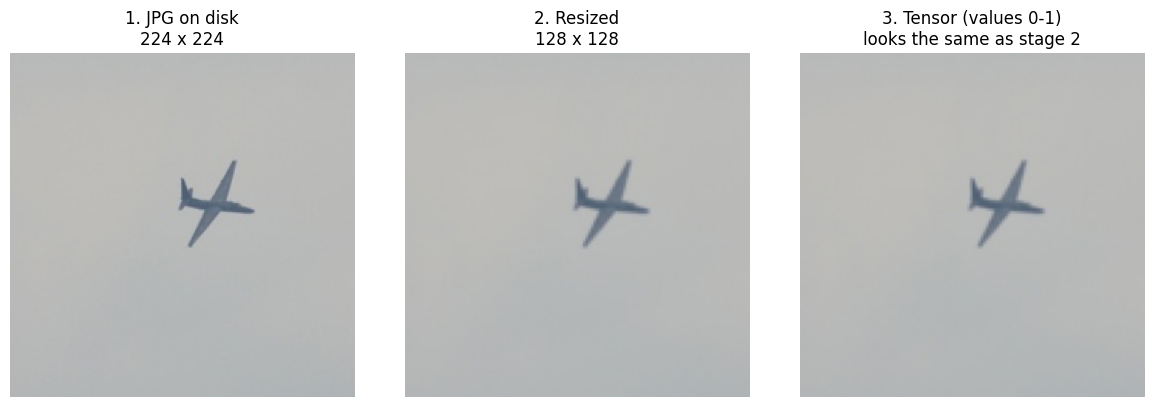

In [40]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Pick one random military training image (Random(0) -> the same image every run)
military_folder = os.path.join(train_dir, "military")
example_name = random.Random(0).choice(sorted(os.listdir(military_folder)))
example_path = os.path.join(military_folder, example_name)

# Stage 1: the JPG on disk
example_image = Image.open(example_path).convert("RGB")
print("1. JPG on disk: size =", example_image.size, "(width, height), values 0-255")

# Stage 2: resize to IMAGE_SIZE x IMAGE_SIZE (only in memory, the file is not changed)
example_resized = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(example_image)
print("2. Resized:     size =", example_resized.size)

# Stage 3: image -> tensor of shape [3, H, W], values divided by 255
example_tensor = transforms.ToTensor()(example_resized)
print("3. Tensor:      shape =", tuple(example_tensor.shape),
      f"| min = {example_tensor.min().item():.2f}, max = {example_tensor.max().item():.2f}")

# Show the 3 stages side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(example_image)
axes[0].set_title(f"1. JPG on disk\n{example_image.size[0]} x {example_image.size[1]}")

axes[1].imshow(example_resized)
axes[1].set_title(f"2. Resized\n{example_resized.size[0]} x {example_resized.size[1]}")

# The tensor is [3, H, W]; matplotlib wants [H, W, 3] -> permute(1, 2, 0)
axes[2].imshow(example_tensor.permute(1, 2, 0))
axes[2].set_title("3. Tensor (values 0-1)\nlooks the same as stage 2")

for ax in axes:
    ax.axis("off")  # hide the x/y axis numbers
plt.tight_layout()
plt.show()

### 6.2 Normalization: the mean and std

`Normalize` computes, for each color channel (R, G, B) separately:

```
value = (value - mean) / std
```

After that, every channel averages about **0** with a spread of about **1**.
This is the same standardization your teacher's `make_nn_moons` does (`(X - mean) / std`).

**Why it helps:** the first layer's weighted sums (`z`) stay in a sensible range, so ReLUs don't
all die or blow up (Lesson 28), and training is more stable with a normal learning rate (Lesson 29).

**Why our own numbers** (not ImageNet's `[0.485, 0.456, 0.406]` that tutorials copy)?
Those only matter for *pretrained* models. Ours starts from scratch, so it should match **our**
images (lots of sky).

**Why only the training images?** Val/test stand in for "new images the model has never seen".
If they influenced the mean/std, a bit of information about them would leak into training
(same rule as fitting a scaler only on `X_train` in scikit-learn).

The function below computes the numbers once and saves them to `mean_std.json` in the processed
folder; after that it just loads the file. It recomputes automatically if you change `IMAGE_SIZE`.

In [41]:
def compute_mean_std(train_dir):
    """
    Returns (mean, std): two lists with one number each for R, G and B,
    computed over the TRAINING images only.
    """

    # Saved next to the split folders, e.g. data/processed/subset_2000_8d56f0/mean_std.json
    stats_path = os.path.join(os.path.dirname(train_dir), "mean_std.json")

    # If it was already computed for this image size, just load it
    if os.path.exists(stats_path) and not FORCE_RECOMPUTE_STATS:
        with open(stats_path) as f:
            saved = json.load(f)
        if saved["image_size"] == IMAGE_SIZE:
            return saved["mean"], saved["std"]

    print("Computing mean/std of the training images (only done once)...")

    # Load the training images WITHOUT random changes and WITHOUT normalizing:
    # just resize and turn into tensors with values 0.0-1.0
    plain_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
    ])
    plain_train_images = datasets.ImageFolder(train_dir, transform=plain_transform)

    # For each color channel, add up every pixel value and every value squared.
    # (float64 = extra precision, so tiny rounding errors don't add up)
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_sum_squared = torch.zeros(3, dtype=torch.float64)
    num_pixels = 0  # pixels per channel, counted over all images

    for image, label in plain_train_images:
        # image has shape [3, H, W]: 3 color channels, each an H x W grid
        image = image.double()
        channel_sum += image.sum(dim=(1, 2))                # sum over height and width
        channel_sum_squared += (image ** 2).sum(dim=(1, 2))
        num_pixels += image.shape[1] * image.shape[2]       # H * W

    # mean = average value; std = sqrt(average of the squares - mean squared)
    mean = channel_sum / num_pixels
    std = torch.sqrt(channel_sum_squared / num_pixels - mean ** 2)

    # Turn into plain Python lists (easy to save as JSON and to print)
    mean, std = mean.tolist(), std.tolist()

    # Save, together with the image size it was computed for
    with open(stats_path, "w") as f:
        json.dump({"image_size": IMAGE_SIZE, "mean": mean, "std": std}, f, indent=2)

    return mean, std

In [42]:
# Compute (first time) or load (after that) the training-set mean/std
mean, std = compute_mean_std(train_dir)

# One number per color channel.
# Expect means roughly 0.3-0.7 and stds roughly 0.15-0.35.
# Something near 0 or above 1 would mean something went wrong.
for channel, m, s in zip(["Red", "Green", "Blue"], mean, std):
    print(f"{channel:5}: mean = {m:.3f}, std = {s:.3f}")

Red  : mean = 0.502, std = 0.229
Green: mean = 0.539, std = 0.216
Blue : mean = 0.571, std = 0.249


Before normalizing: min = 0.31, max = 0.75, average = 0.72
After normalizing:  min = -0.84, max = 1.08, average = 0.80


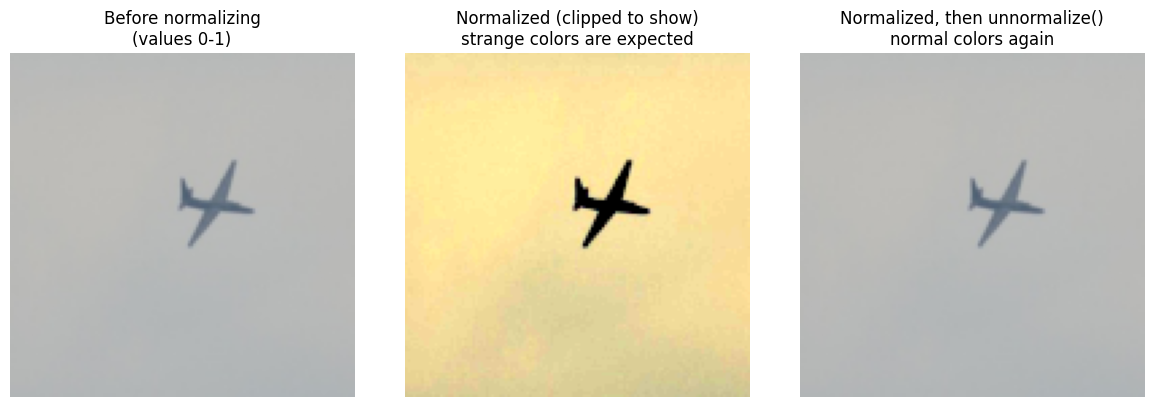

In [43]:
# ======================================================================
# PARTLY DEMO:
# - the unnormalize() function is NEEDED (later cells use it to show images)
# - everything below the function is demo only
# ======================================================================

def unnormalize(image, mean, std):
    """
    Undo the normalization so a tensor can be SHOWN with normal colors.
    image: one normalized tensor of shape [3, H, W]
    Returns a [H, W, 3] tensor with values 0-1 that matplotlib can show.
    """
    mean = torch.tensor(mean).view(3, 1, 1)  # shape [3, 1, 1] -> applies per color channel
    std = torch.tensor(std).view(3, 1, 1)
    image = image * std + mean               # reverse of (value - mean) / std
    image = image.clamp(0, 1)                # keep values in the valid 0-1 range
    return image.permute(1, 2, 0)            # [3, H, W] -> [H, W, 3] for matplotlib


# ----- DEMO ONLY from here down -----
# Stage 4 of the example image from 6.1: normalize it
example_normalized = transforms.Normalize(mean, std)(example_tensor)
print("Before normalizing:",
      f"min = {example_tensor.min().item():.2f}, max = {example_tensor.max().item():.2f},",
      f"average = {example_tensor.mean().item():.2f}")
print("After normalizing: ",
      f"min = {example_normalized.min().item():.2f}, max = {example_normalized.max().item():.2f},",
      f"average = {example_normalized.mean().item():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(example_tensor.permute(1, 2, 0))
axes[0].set_title("Before normalizing\n(values 0-1)")

# Normalized values go below 0 and above 1, which matplotlib can't show properly.
# Clipping them to 0-1 just to SHOW them gives strange colors - that's expected.
# (The CNN gets the real normalized numbers, not this clipped picture.)
axes[1].imshow(example_normalized.permute(1, 2, 0).clamp(0, 1))
axes[1].set_title("Normalized (clipped to show)\nstrange colors are expected")

# The fix for showing normalized images: undo the normalization first
axes[2].imshow(unnormalize(example_normalized, mean, std))
axes[2].set_title("Normalized, then unnormalize()\nnormal colors again")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 6.3 Augmentation (training images only)

**Augmentation** = small random changes applied to a training image **every time it is loaded**.
Over 30 epochs the model sees 30 slightly different versions of each photo.

**Why:** we have only ~530 training images per class, and a CNN trained from scratch will happily
**memorize** them (training loss keeps falling while validation loss rises = overfitting, Lesson 29).
Random changes make memorizing harder, so the model has to learn the aircraft itself.

**Two common misunderstandings:**
- It does **not** create new files or make the dataset bigger on disk. It happens in memory, on the fly.
- It is for **training only**. Val/test must stay the same, so their scores can be trusted.

**The rule:** only use changes that keep the correct answer the same **and** could really happen in a photo.

| Change | Setting | Why it is OK |
|---|---|---|
| `RandomResizedCrop` | keeps 70-100% of the image | aircraft are photographed at different distances. Kept **mild**: a big zoom could cut the plane out, leaving only sky labelled "military" |
| `RandomHorizontalFlip` | half of the time | a plane facing left is still the same plane facing right |
| `RandomRotation` | -10 to +10 degrees | aircraft bank and climb (the empty corners are filled with black) |
| `ColorJitter` | brightness / contrast / saturation +-20%, **no hue** | weather and time of day. A green sky would not be realistic |

**Left out on purpose:** vertical flip (upside-down airliners), hue changes (green skies),
heavy blur/noise (small birds and drones in `neither` could disappear).

In [44]:
# TRAIN transform: random changes ("augmentation"), different every time an image is loaded
train_transform = transforms.Compose([
    # Cut out a random piece covering 70-100% of the image, then resize it to IMAGE_SIZE.
    # Acts like a small zoom. Kept mild so the aircraft isn't cut out.
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),

    # Mirror left <-> right half of the time
    transforms.RandomHorizontalFlip(),

    # Rotate by a random angle between -10 and +10 degrees
    transforms.RandomRotation(10),

    # Randomly change brightness, contrast and saturation by up to 20% (no hue change)
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    # Image -> tensor [3, H, W] with values 0.0-1.0
    transforms.ToTensor(),

    # value = (value - mean) / std, per color channel (6.2)
    transforms.Normalize(mean, std),
])

# VAL/TEST transform: NO random changes, so the scores are the same every time
eval_transform = transforms.Compose([
    # Just resize the whole image (no cropping)
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

print("TRAIN transform (random changes):")
print(train_transform)
print()
print("VAL/TEST transform (no random changes):")
print(eval_transform)

TRAIN transform (random changes):
Compose(
    RandomResizedCrop(size=(128, 128), scale=(0.7, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.5015376777839903, 0.5385182437524162, 0.571061075127874], std=[0.2285306894859499, 0.21639080940454927, 0.24888060803832343])
)

VAL/TEST transform (no random changes):
Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5015376777839903, 0.5385182437524162, 0.571061075127874], std=[0.2285306894859499, 0.21639080940454927, 0.24888060803832343])
)


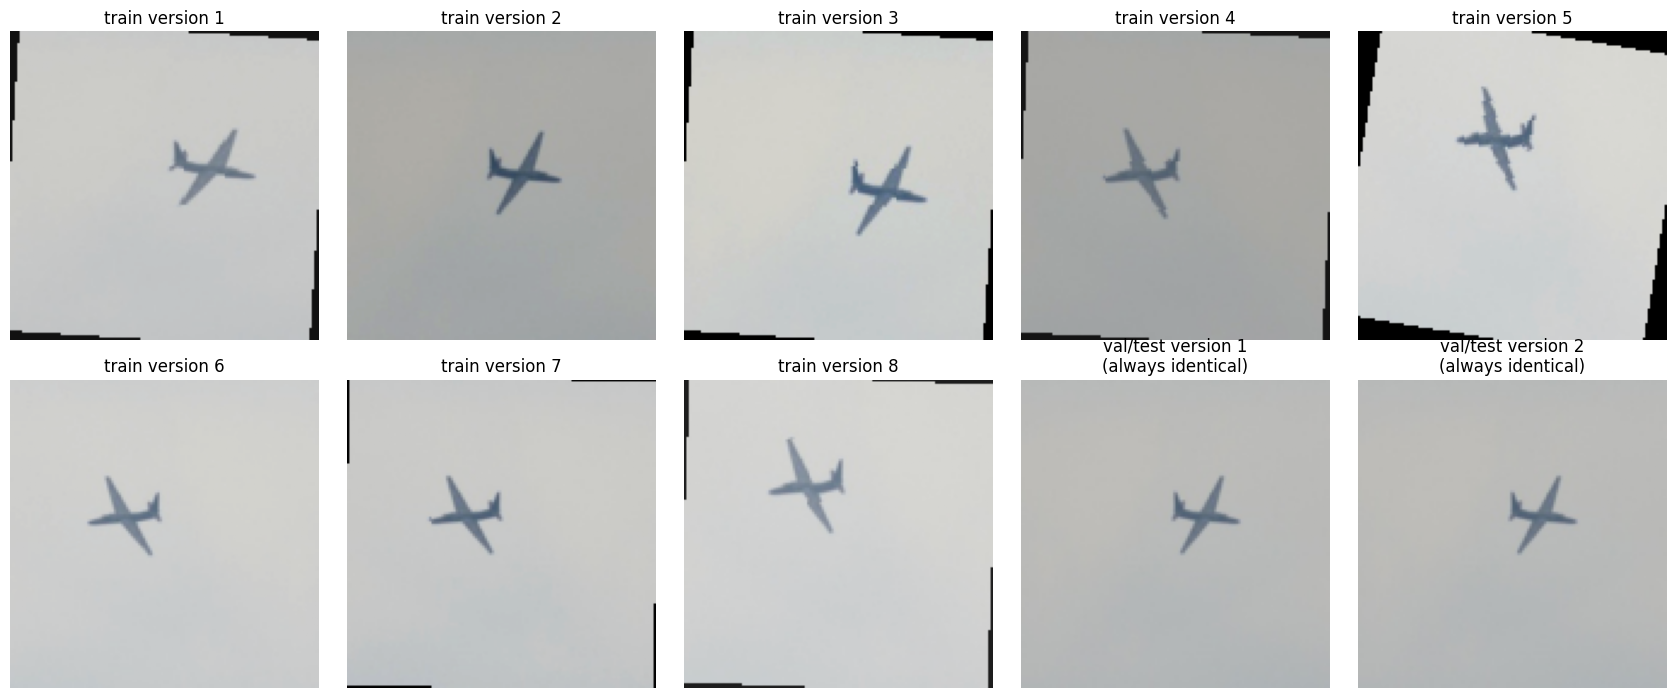

val/test versions identical: True
train versions identical:    False


In [45]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Send the SAME example image (from 6.1) through the TRAIN transform 8 times.
# Every call picks new random changes, so all 8 results look a bit different.
fig, axes = plt.subplots(2, 5, figsize=(17, 7))

for i in range(8):
    augmented = train_transform(example_image)  # new random zoom/flip/rotation/colors each time
    ax = axes[i // 5][i % 5]                    # fill the grid row by row
    ax.imshow(unnormalize(augmented, mean, std))
    ax.set_title(f"train version {i + 1}")
    ax.axis("off")

# The last 2 spots: the VAL/TEST transform, twice -> exactly the same picture both times
for j in range(2):
    fixed = eval_transform(example_image)
    ax = axes[1][3 + j]
    ax.imshow(unnormalize(fixed, mean, std))
    ax.set_title(f"val/test version {j + 1}\n(always identical)")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Prove it with numbers: two val/test versions are exactly equal, two train versions are not
print("val/test versions identical:",
      torch.equal(eval_transform(example_image), eval_transform(example_image)))
print("train versions identical:   ",
      torch.equal(train_transform(example_image), train_transform(example_image)))

### 6.4 Labels from folder names (`ImageFolder`) and the class order

`torchvision.datasets.ImageFolder` uses the **folder name as the label**:
every image in `train/military/` is labelled "military", and so on.
That's exactly the folder layout step 4 makes.

It gives each class a number in **alphabetical order**:

| Folder | Label number |
|---|---|
| `civilian` | 0 |
| `military` | 1 |
| `neither` | 2 |

**Watch out:** step 5 uses `CLASSES = ["military", "civilian", "neither"]`, a **different** order.
If we used that list to turn the model's output number back into a name, every civilian/military
prediction would get the wrong name, and nothing would crash to warn us.
So from now on we always use **`class_names`** (from `ImageFolder`).

Each split gets its own dataset: train uses the **train** transform, val/test use the **val/test** transform.

In [46]:
# One dataset per split. The folder name is the label.
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)  # random changes
val_dataset = datasets.ImageFolder(val_dir, transform=eval_transform)       # no random changes
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)     # no random changes

# Safety check: all 3 splits must use the same class numbering,
# otherwise label 1 could mean different things in train and test
if not (train_dataset.classes == val_dataset.classes == test_dataset.classes):
    raise ValueError("train/val/test have different class folders!")

# The class names, in label-number order. Use THIS list from now on.
class_names = train_dataset.classes

print("Folder name -> label number:", train_dataset.class_to_idx)
print("class_names:                ", class_names)
print("Same order as step 5's CLASSES?", class_names == CLASSES)

# One item of a dataset = (image tensor, label number)
first_image, first_label = train_dataset[0]
print()
print("train_dataset[0] -> image shape", tuple(first_image.shape),
      "| label", first_label, "=", class_names[first_label])

# Count the images per split and class.
# dataset.targets = the label number of every image. These should match step 5's counts.
print()
for split, dataset in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]:
    for label_number, name in enumerate(class_names):
        print(f"{split:5} {name:9} {dataset.targets.count(label_number):5} images")

Folder name -> label number: {'civilian': 0, 'military': 1, 'neither': 2}
class_names:                 ['civilian', 'military', 'neither']
Same order as step 5's CLASSES? False

train_dataset[0] -> image shape (3, 128, 128) | label 0 = civilian

train civilian   1472 images
train military   1472 images
train neither     616 images
val   civilian    184 images
val   military    184 images
val   neither      77 images
test  civilian    184 images
test  military    184 images
test  neither      77 images


### 6.5 Batches (`DataLoader`) and why training images are shuffled

A **batch** is a group of images the model processes together before **one** weight update.

```
~1,600 training images / 32 per batch = ~50 batches = ~50 weight updates per epoch
```

(Your teacher's `MultiLayerPerceptron.fit` used **all** training points at once = 1 update per epoch.
That works for 50 points with 2 numbers each, but not for thousands of images.)

Each batch is two tensors:
- `images`: `[32, 3, IMAGE_SIZE, IMAGE_SIZE]` = 32 images x 3 color channels x height x width
- `labels`: `[32]` = one label number per image (`labels[i]` belongs to `images[i]`)

All 32 images must have the **same** height and width so they can be stacked into one tensor
(like a stack of same-size sheets of paper). That's one reason every image is resized.

**Why shuffle the training images?** `ImageFolder` lists images folder by folder (alphabetically).
Without shuffling, the first ~17 batches would be **only civilian**, then only military, then only neither.
The model would learn "always say civilian", then swing to "always say military", and so on.
Shuffling mixes the classes in every batch, with a new order every epoch.
The fixed `SEED` makes the "random" order the same every run (like `random_state=1` in `MLPClassifier`).

**No class-balancing trick is needed:** step 3 already picks equal thirds of each class.

In [47]:
# A random generator with a fixed seed -> the same shuffle order every run
shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(SEED)

# Train: shuffled (mixed classes in every batch, new order every epoch)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=shuffle_generator,
    num_workers=NUM_WORKERS,
)

# Val/test: NOT shuffled (fixed order -> prediction #i always belongs to image #i)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# Everything needed later to use the trained model on new images the SAME way.
# It gets saved next to the model in the training step (config.json).
data_info = {
    "class_names": class_names,
    "mean": mean,
    "std": std,
    "image_size": IMAGE_SIZE,
}

print("Batches per epoch:")
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    print(f"  {split:5}: {len(loader.dataset):5} images -> {len(loader):3} batches of up to {loader.batch_size}")

Batches per epoch:
  train:  3560 images -> 112 batches of up to 32
  val  :   445 images ->  14 batches of up to 32
  test :   445 images ->  14 batches of up to 32


In [48]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Take ONE training batch and look at its shapes
images, labels = next(iter(train_loader))

print("images shape:", tuple(images.shape), " = [batch size, color channels, height, width]")
print("labels shape:", tuple(labels.shape), "        = [batch size]")
print("first 10 labels:", labels[:10].tolist())
print("as class names: ", [class_names[label] for label in labels[:10].tolist()])

images shape: (32, 3, 128, 128)  = [batch size, color channels, height, width]
labels shape: (32,)         = [batch size]
first 10 labels: [1, 0, 1, 1, 2, 1, 1, 0, 1, 1]
as class names:  ['military', 'civilian', 'military', 'military', 'neither', 'military', 'military', 'civilian', 'military', 'military']


In [49]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Compare the first batch WITH shuffling vs. WITHOUT shuffling

def count_classes(batch_labels):
    # How many images of each class are in a batch of labels
    return {name: (batch_labels == number).sum().item() for number, name in enumerate(class_names)}

# WITH shuffling (our real train_loader): classes are mixed
_, shuffled_labels = next(iter(train_loader))
print("First batch WITH shuffling:   ", count_classes(shuffled_labels))

# WITHOUT shuffling (built here only for comparison, not used for training): all one class
unshuffled_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
_, unshuffled_labels = next(iter(unshuffled_loader))
print("First batch WITHOUT shuffling:", count_classes(unshuffled_labels))

First batch WITH shuffling:    {'civilian': 18, 'military': 7, 'neither': 7}
First batch WITHOUT shuffling: {'civilian': 32, 'military': 0, 'neither': 0}


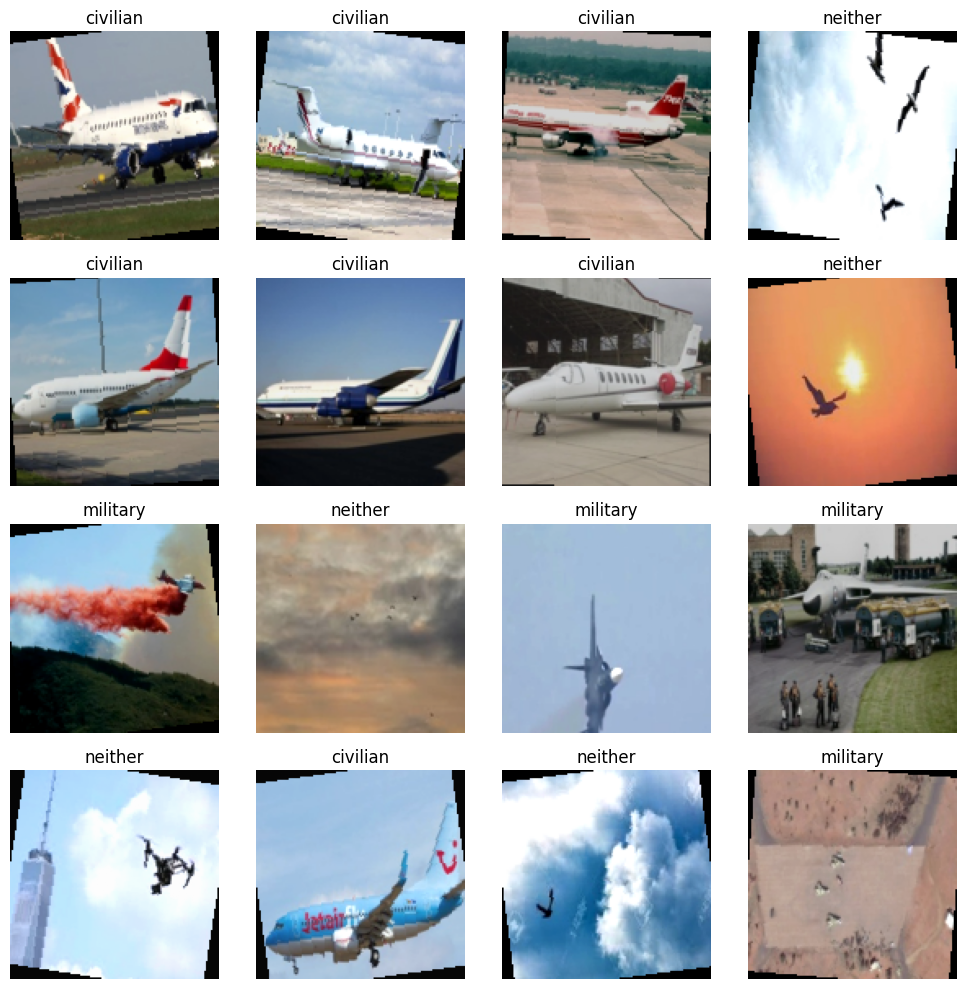

In [50]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Show the first 16 images of one shuffled training batch with their class names.
# They include the random changes from 6.3. Run again to see a different batch.
# Check: the aircraft is visible in every military/civilian image, and the labels are right.
GRID_SIZE = 4  # 4 x 4 = 16 images

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(GRID_SIZE, GRID_SIZE, figsize=(10, 10))

for i in range(GRID_SIZE * GRID_SIZE):
    ax = axes[i // GRID_SIZE][i % GRID_SIZE]       # row = i // 4, column = i % 4
    ax.imshow(unnormalize(images[i], mean, std))   # undo normalization to show normal colors
    ax.set_title(class_names[labels[i].item()])    # label number -> class name
    ax.axis("off")

plt.tight_layout()
plt.show()

### 6.6 Why val/test are NOT shuffled and NOT augmented

- **Not augmented:** their job is to give a **trustworthy score**. If their images changed randomly,
  the score would change every time we measured it.
- **Not shuffled:** shuffling only helps *learning*, and the model never learns from val/test.
  Accuracy is the same in any order. A **fixed** order also means prediction #i always belongs to
  image #i, which we need later to show the misclassified images
  (like `mis_indices_svm` in the MNIST homework).

The cell below loads the first val batch twice and the first train batch twice and compares them.

In [51]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Val: the first batch is IDENTICAL every time (same images, same order, no random changes)
val_images_1, val_labels_1 = next(iter(val_loader))
val_images_2, val_labels_2 = next(iter(val_loader))
print("Val first batch identical both times:  ",
      torch.equal(val_images_1, val_images_2) and torch.equal(val_labels_1, val_labels_2))

# Train: the first batch is DIFFERENT every time (new shuffle order + new random changes)
train_images_1, _ = next(iter(train_loader))
train_images_2, _ = next(iter(train_loader))
print("Train first batch identical both times:", torch.equal(train_images_1, train_images_2))

Val first batch identical both times:   True
Train first batch identical both times: False


## 7. Build the CNN

This section builds the model's **layers**. It does **not** train it yet (that's section 8),
so right now every weight is random.

### The architecture

Four identical **blocks**, each the Lesson 31 pattern **Conv -> ReLU -> Max-Pool** (plus BatchNorm),
then a small **head** that turns the features into 3 class scores:

```
Input batch                                                  [32,   3, 128, 128]
Block 1: Conv 3x3 (32 filters)  + BatchNorm + ReLU + MaxPool  -> [32,  32,  64,  64]
Block 2: Conv 3x3 (64 filters)  + BatchNorm + ReLU + MaxPool  -> [32,  64,  32,  32]
Block 3: Conv 3x3 (128 filters) + BatchNorm + ReLU + MaxPool  -> [32, 128,  16,  16]
Block 4: Conv 3x3 (256 filters) + BatchNorm + ReLU + MaxPool  -> [32, 256,   8,   8]
Global average pooling (each 8x8 map -> 1 number)             -> [32, 256]
Dropout (30%)                                                 -> [32, 256]
Linear 256 -> 3                                               -> [32,   3]   one score per class
```

| Piece | What it does | Lesson |
|---|---|---|
| **Conv 3x3, padding 1** | slides small filters over neighboring pixels to detect patterns. Padding 1 keeps the size the same: `O = (W - K + 2P)/S + 1 = (128 - 3 + 2)/1 + 1 = 128` | 31 |
| **Filters are learned** | unlike Lesson 31's hand-picked kernels (`HorizontalEdge`, ...), every filter starts random and training adjusts it | 29 (backprop) |
| **Filters grow 32 -> 256** | early blocks find simple things (edges, colors), later blocks combine them into complex parts (wings, rotors). Each halving of the size is paired with a doubling of the filters | 30 |
| **BatchNorm** | re-normalizes each filter's outputs during training: the same idea as normalizing the input images (6.2), but **inside** the network. Makes training from scratch much more stable | new |
| **ReLU** | the non-linearity. No vanishing gradients like sigmoid | 28, 30 |
| **MaxPool 2x2** | halves height and width, keeping the strongest response -> some tolerance to shifts | 31 |
| **Global average pooling** | averages each of the 256 feature maps to 1 number, so the head doesn't depend on the image size and has few weights | |
| **Dropout 30%** | during training, randomly switches off 30% of the 256 features, so the model can't rely on any single one (fights overfitting). Turned off automatically when evaluating | 29 |
| **Linear 256 -> 3** | weighted sums `z = w . x + b` turning the 256 features into 3 scores (civilian, military, neither) | 28 |

**No softmax at the end.** The model outputs raw scores (called **logits**), e.g. `[1.2, -0.3, 0.4]`.
The loss function in section 8 (`CrossEntropyLoss`) applies softmax itself. Adding our own softmax
layer would apply it twice, a common bug. To get probabilities ourselves we call `torch.softmax` (see 7.6).
The **predicted class** is simply the one with the highest score.

### 7.1 Device: where the math runs

- **`mps`** = the GPU in your Mac (Apple Silicon). Much faster for CNNs.
- **`cuda`** = an NVIDIA GPU (on other computers).
- **`cpu`** = the normal processor. Always works, but slower.

The model **and** every batch of images must be on the **same** device, so we move both there with `.to(device)`.

In [52]:
# Use the fastest device that is available
if torch.backends.mps.is_available():
    device = torch.device("mps")   # Mac GPU (Apple Silicon)
elif torch.cuda.is_available():
    device = torch.device("cuda")  # NVIDIA GPU
else:
    device = torch.device("cpu")   # normal processor (slower, but always works)

print("Using device:", device)

Using device: mps


### 7.2 One conv block

All 4 blocks have the same 4 layers; only the number of filters changes. So instead of writing
them out 4 times, `conv_block()` builds one block for any number of input and output channels.

- **`in_channels`**: how many feature maps come **in** (3 for the first block: R, G, B).
- **`out_channels`**: how many filters this block has = how many feature maps go **out**.
- Each filter is really `3 x 3 x in_channels`: it looks at a 3 x 3 patch of **all** incoming maps at once.

`nn.Sequential` chains layers: the output of one becomes the input of the next, in the order listed.

In [53]:
def conv_block(in_channels, out_channels):
    """
    One block: Conv 3x3 -> BatchNorm -> ReLU -> MaxPool 2x2.
    Input  shape: [batch, in_channels,  H,     W    ]
    Output shape: [batch, out_channels, H / 2, W / 2]
    """
    return nn.Sequential(
        # out_channels filters, each 3 x 3 x in_channels.
        # padding=1 keeps H and W the same (Lesson 31 formula with K=3, P=1, S=1).
        # bias=False: the BatchNorm right after has its own shift, so a bias here would be wasted.
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),

        # Re-normalize each of the out_channels feature maps (average ~0, spread ~1),
        # then scale/shift them with 2 learned numbers per map
        nn.BatchNorm2d(out_channels),

        # Keep positive values, turn negative values into 0
        nn.ReLU(),

        # Keep the largest value in every 2 x 2 window -> halves H and W
        nn.MaxPool2d(kernel_size=2),
    )

### 7.3 The model (`AircraftCNN`)

In PyTorch, a model is a **class** that inherits from `nn.Module`. It has two parts:

- **`__init__`**: creates the layers (and their weights) **once**, when the model is made.
- **`forward(x)`**: says **in which order** a batch `x` flows through those layers.
  You never call `forward` yourself: `model(images)` calls it for you.

`super().__init__()` must be the first line of `__init__`: it sets up the `nn.Module` machinery that
keeps track of all the weights (so the optimizer can find them in section 8).

**Settings** at the top of the cell:
- `CHANNELS`: the number of filters in each block. One entry = one block, so the list's length
  is the number of blocks. Try e.g. `[16, 32, 64, 128]` (smaller) or `[32, 64, 128, 256, 256]` (5 blocks).
- `DROPOUT`: fraction of features switched off during training.

The weights start **random**. `torch.manual_seed(SEED)` makes them the **same** random numbers every run.

In [54]:
# --- Settings for the model ---

# Number of filters in each block (one entry = one block)
CHANNELS = [32, 64, 128, 256]

# Fraction of the features switched off (randomly) during training
DROPOUT = 0.3

# One output score per class (3: civilian, military, neither)
NUM_CLASSES = len(class_names)


class AircraftCNN(nn.Module):

    def __init__(self, channels=CHANNELS, dropout=DROPOUT, num_classes=NUM_CLASSES):
        super().__init__()  # sets up nn.Module so it can keep track of all the weights

        # --- The feature extractor: one conv block per entry in `channels` ---
        blocks = []
        in_channels = 3  # the first block gets the 3 color channels (R, G, B)
        for out_channels in channels:
            blocks.append(conv_block(in_channels, out_channels))
            in_channels = out_channels  # the next block gets this block's feature maps
        self.features = nn.Sequential(*blocks)  # chain the blocks: block 1 -> block 2 -> ...

        # --- The head: turns the feature maps into class scores ---
        # Average each feature map down to 1 number: [batch, 256, 8, 8] -> [batch, 256, 1, 1]
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        # Drop the two 1-sized dimensions: [batch, 256, 1, 1] -> [batch, 256]
        self.flatten = nn.Flatten()
        # Randomly switch off some features during training (off automatically when evaluating)
        self.dropout = nn.Dropout(dropout)
        # Weighted sums: 256 features -> 3 class scores
        self.classifier = nn.Linear(channels[-1], num_classes)

    def forward(self, x):
        # x: a batch of images, shape [batch, 3, IMAGE_SIZE, IMAGE_SIZE]
        x = self.features(x)     # -> [batch, 256, 8, 8]   (with IMAGE_SIZE = 128)
        x = self.global_pool(x)  # -> [batch, 256, 1, 1]
        x = self.flatten(x)      # -> [batch, 256]
        x = self.dropout(x)      # -> [batch, 256]   (same shape, some values set to 0 in training)
        x = self.classifier(x)   # -> [batch, 3]     raw scores (logits), NOT probabilities
        return x


# Create the model. Fixed seed -> the same random starting weights every run.
torch.manual_seed(SEED)
model = AircraftCNN().to(device)  # .to(device): put all its weights on the GPU (or CPU)

print(model)

AircraftCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      

### 7.4 How many weights? (and why CNNs need so few)

Every filter has `3 x 3 x in_channels` weights, and the **same** filter is reused at every position
of the image (**weight sharing**, Lesson 31). So the number of weights does **not** depend on the image size.

The cell below counts the weights in each part of the model and compares with a plain dense
(fully connected) layer that would connect the flattened 128 x 128 x 3 image to just 256 neurons.

In [55]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# Count the weights (numbers training can change) in a part of the model
def count_weights(part):
    return sum(p.numel() for p in part.parameters())

print(f"{'Part':38} {'Weights':>10}")
print("-" * 50)
in_ch = 3
for i, block in enumerate(model.features):
    out_ch = CHANNELS[i]
    print(f"Block {i + 1}: {out_ch:3} filters of 3x3x{in_ch:<3}       {count_weights(block):>10,}")
    in_ch = out_ch
print(f"Head: Linear {CHANNELS[-1]} -> {NUM_CLASSES}{'':20} {count_weights(model.classifier):>10,}")
print("-" * 50)
total_weights = count_weights(model)
print(f"{'Total':38} {total_weights:>10,}")

# A single dense layer from the flattened image (128*128*3 inputs) to 256 neurons
dense_inputs = IMAGE_SIZE * IMAGE_SIZE * 3
dense_weights = dense_inputs * 256 + 256  # every input to every neuron, + one bias per neuron
print()
print(f"One dense layer, {dense_inputs:,} inputs -> 256 neurons: {dense_weights:,} weights")
print(f"-> about {dense_weights / total_weights:.0f}x more than our WHOLE CNN, for just one layer")

Part                                      Weights
--------------------------------------------------
Block 1:  32 filters of 3x3x3                928
Block 2:  64 filters of 3x3x32            18,560
Block 3: 128 filters of 3x3x64            73,984
Block 4: 256 filters of 3x3x128          295,424
Head: Linear 256 -> 3                            771
--------------------------------------------------
Total                                     389,667

One dense layer, 49,152 inputs -> 256 neurons: 12,583,168 weights
-> about 32x more than our WHOLE CNN, for just one layer


### 7.5 Follow one batch through the model

Here a real batch goes through the model **one layer at a time**, printing the shape after each,
so you can see the diagram from the top of section 7 actually happen.

We use a **val** batch (not train) on purpose: taking batches from `train_loader` moves its shuffle order
forward, which would change the training run in section 8.

`model.eval()` switches the model to "evaluation mode" (dropout off, BatchNorm uses fixed numbers), and
`torch.no_grad()` tells PyTorch not to prepare for backprop, since we're not training here.

In [56]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

# One val batch, moved to the same device as the model
images, labels = next(iter(val_loader))
x = images.to(device)

model.eval()           # evaluation mode: dropout off
with torch.no_grad():  # no backprop needed here
    print(f"{'Input':28} {tuple(x.shape)}")

    # The 4 conv blocks, one at a time
    for i, block in enumerate(model.features):
        x = block(x)
        print(f"{f'After block {i + 1}':28} {tuple(x.shape)}")

    # The head, one layer at a time
    x = model.global_pool(x)
    print(f"{'After global average pool':28} {tuple(x.shape)}")
    x = model.flatten(x)
    print(f"{'After flatten':28} {tuple(x.shape)}")
    x = model.dropout(x)
    print(f"{'After dropout':28} {tuple(x.shape)}   (does nothing in eval mode)")
    x = model.classifier(x)
    print(f"{'After linear (output)':28} {tuple(x.shape)}   <- one score per class")

print()
print("Scores for the first image:", [round(v, 3) for v in x[0].tolist()])

Input                        (32, 3, 128, 128)
After block 1                (32, 32, 64, 64)
After block 2                (32, 64, 32, 32)
After block 3                (32, 128, 16, 16)
After block 4                (32, 256, 8, 8)
After global average pool    (32, 256, 1, 1)
After flatten                (32, 256)
After dropout                (32, 256)   (does nothing in eval mode)
After linear (output)        (32, 3)   <- one score per class

Scores for the first image: [0.023, 0.037, 0.023]


### 7.6 Check the untrained model

Before training, the weights are random, so the model should have **no idea**:

- It should give each class roughly the same probability, about **1/3 = 33%**.
- Its loss (cross-entropy, used in section 8) should be about **ln(3) = 1.10**.
  Cross-entropy is `-ln(probability given to the correct class)`, and `-ln(1/3) = 1.10`.

If the loss is far above 1.10 (say 3 or more), the untrained model is already very confident about
random answers, which usually means something is wired wrong. It's a good habit to check this
**before** spending time on training.

`torch.softmax` turns the 3 raw scores into 3 probabilities that add up to 1.

In [57]:
# ======================================================================
# DEMO ONLY - not needed for training.
# This cell just shows you what is happening. Safe to skip.
# ======================================================================

loss_function = nn.CrossEntropyLoss()  # the same loss section 8 will train with

model.eval()
all_scores, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:         # all 201 val images, 32 at a time
        scores = model(images.to(device))     # raw scores, shape [batch, 3]
        all_scores.append(scores.cpu())       # .cpu(): bring back from the GPU
        all_labels.append(labels)

scores = torch.cat(all_scores)  # [201, 3]
labels = torch.cat(all_labels)  # [201]

loss = loss_function(scores, labels).item()
print(f"Loss of the untrained model: {loss:.3f}   (expected about ln(3) = 1.099)")

# Average probability the model gives to each class
probabilities = torch.softmax(scores, dim=1)  # each row now adds up to 1
print()
print("Average probability per class (expected about 0.33 each):")
for number, name in enumerate(class_names):
    print(f"  {name:9} {probabilities[:, number].mean().item():.3f}")

# How often each class is the model's guess (the class with the highest score)
predictions = scores.argmax(dim=1)
accuracy = (predictions == labels).float().mean().item()
print()
print("How often each class is guessed:",
      {name: (predictions == number).sum().item() for number, name in enumerate(class_names)})
print(f"Accuracy: {accuracy:.1%}   (random guessing between 3 classes = about 33%)")

Loss of the untrained model: 1.097   (expected about ln(3) = 1.099)

Average probability per class (expected about 0.33 each):
  civilian  0.333
  military  0.337
  neither   0.331

How often each class is guessed: {'civilian': 18, 'military': 412, 'neither': 15}
Accuracy: 37.5%   (random guessing between 3 classes = about 33%)


## 8. Train the CNN (or load it if already trained)

Right now the model has **random weights**: it guesses (loss about 1.10, accuracy about 33%, see 7.6).
Training adjusts its 389,667 weights a little at a time until its guesses match the labels.

### What one epoch does

```
TRAIN (model.train(): dropout ON)
    for each of the 50 batches of training images:
        1. forward:   scores = model(images)
        2. loss:      how wrong the scores are (cross-entropy)
        3. backprop:  loss.backward()   -> a gradient for every weight
        4. update:    optimizer.step()  -> W = W - learning rate x gradient
CHECK (model.eval(): dropout OFF, no updates)
    score the 201 val images -> val loss and val accuracy
KEEP THE BEST
    lowest val loss so far? -> save these weights (best.pt)
STOP EARLY
    val loss hasn't improved for PATIENCE epochs? -> stop
```

This is the same loop as your teacher's `MultiLayerPerceptron.fit` (Lesson 29), except in batches,
and PyTorch does the backprop math for us.

### Train or load

Like steps 3 and 4 ("Subset already exists", "Already processed"), training is skipped if it was already done:

- **Same settings already trained to the end** -> load the saved model (about a second).
- **Same settings, but training was interrupted** (you pressed Stop, the laptop slept, an error) -> the unfinished
  run folder is **deleted completely** and the model is trained again from epoch 1. Only finished runs are ever kept.
- **New settings** -> train from scratch. Every combination of settings gets its own folder in `runs/`,
  so older models are kept for comparing.

**Important:** "same settings" means the **settings variables** (`IMAGE_SIZE`, `CHANNELS`, `LEARNING_RATE`, ...).
If you change the **code** (e.g. add a layer to `AircraftCNN` or an augmentation to `train_transform`)
without changing a setting, set `FORCE_RETRAIN = True` once, otherwise the old model is loaded.

### Sections
- **8.1** Settings
- **8.2** Run folder: where this model is saved, and was it trained already?
- **8.3** Loss, optimizer and learning-rate schedule
- **8.4** The training and evaluation functions
- **8.5** Overfit check (check only): can the model learn at all?
- **8.6** Train or load
- **8.7** Learning curves: training loss vs. validation loss

### 8.1 Settings

| Setting | What it is | Lesson |
|---|---|---|
| `LEARNING_RATE` | step size of each weight update. Too small = slow, too big = loss jumps around | 29 |
| `WEIGHT_DECAY` | L2 regularization: gently pulls weights toward 0 so the model can't memorize with huge weights (like `L2_LAMBDA`) | 29 |
| `EPOCHS` | the **maximum** number of passes over all 1,599 training images (1 epoch = 50 batches = 50 updates) | |
| `PATIENCE` | early stopping: stop if val loss hasn't improved for this many epochs in a row | 29 |
| `FORCE_RETRAIN` | `True` = train again even if a finished model exists (use after changing the code) | |

In [65]:
# --- Settings for training ---

# Step size of each weight update (0.001 is the usual starting value for AdamW)
LEARNING_RATE = 1e-3

# L2 regularization strength (like L2_LAMBDA in Lesson 29)
WEIGHT_DECAY = 5e-4

# Maximum number of passes over all training images
EPOCHS = 60

# Early stopping: stop if val loss hasn't improved for this many epochs in a row
PATIENCE = 20

# True = train again even if a finished model with the same settings exists
# (needed after changing the CODE without changing any setting)
FORCE_RETRAIN = False

# Folder where all trained models are saved (one subfolder per combination of settings)
RUNS_DIR = "runs"

### 8.2 Run folder: where is this model saved, and was it trained already?

All the settings that change the result are turned into a short code, exactly like `make_subset.py`
names its subset files:

```
subset + IMAGE_SIZE + BATCH_SIZE + SEED + CHANNELS + DROPOUT + LEARNING_RATE + WEIGHT_DECAY + EPOCHS + PATIENCE
   -> code "a1b2c3"  ->  runs/subset_2000_8d56f0__a1b2c3/
```

Same settings -> same code -> same folder. Change any setting -> new folder (the old model is kept).

What ends up in the folder:

| File | What it holds | Used for |
|---|---|---|
| `best.pt` | the weights from the epoch with the lowest val loss | **the model** (loaded and tested later) |
| `history.json` | loss and accuracy for every epoch | drawing the learning curves without retraining |
| `training_vs_validation_loss_and_accuracy.png` | the learning-curve figure from 8.7 | looking at the training result without opening the notebook |
| `config.json` | the settings + `class_names`, `mean`, `std`, `image_size` + `"finished": true` | rebuilding the model and preparing new images **the same way** |

`config.json` is written only at the **very end** of training. So if it exists with `"finished": true`,
training completed. An unfinished run never gets it, and its whole folder is deleted (see 8.6).

In [66]:
# All the settings that change the trained model
run_settings = {
    "subset": os.path.basename(processed_dir),  # which data, e.g. subset_2000_8d56f0
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "channels": CHANNELS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "epochs": EPOCHS,
    "patience": PATIENCE,
}

# Turn the settings into a short code, e.g. "a1b2c3". Same settings -> same code.
settings_text = json.dumps(run_settings, sort_keys=True)
run_code = hashlib.md5(settings_text.encode()).hexdigest()[:6]

# This run's folder and files
run_dir = os.path.join(RUNS_DIR, f"{run_settings['subset']}__{run_code}")
best_path = os.path.join(run_dir, "best.pt")
history_path = os.path.join(run_dir, "history.json")
config_path = os.path.join(run_dir, "config.json")


def run_is_finished():
    # True if config.json exists and says the training finished
    if not os.path.exists(config_path):
        return False
    with open(config_path) as f:
        return json.load(f).get("finished", False)


# Say what section 8.6 is going to do
print("Run folder:", run_dir)
if FORCE_RETRAIN:
    print("-> FORCE_RETRAIN is True: will train from scratch")
elif run_is_finished():
    print("-> Finished model found: will LOAD it (no training)")
elif os.path.exists(run_dir):
    print("-> Unfinished run found: will DELETE it and TRAIN from scratch")
else:
    print("-> No model yet: will TRAIN")

Run folder: runs/subset_4450_b187ce__7a9e53
-> Finished model found: will LOAD it (no training)


### 8.3 Loss, optimizer and learning-rate schedule

**Loss: `CrossEntropyLoss`.** Measures how wrong the model is: `-ln(probability given to the correct class)`.
It's the 3-class version of the BCE loss from your homework. It applies softmax to the raw scores itself
(that's why the model has no softmax layer).
- confident and right -> about 0
- random guessing -> 1.10
- confident and wrong -> large

**Optimizer: AdamW.** The part that updates the weights. It's gradient descent (`W = W - lr x gradient`)
with two improvements:
1. it adapts the step size **per weight** (weights with steady gradients take careful steps, rarely-updated ones bigger steps),
2. it applies the weight decay (L2) correctly (that's the "W").
It usually trains CNNs faster and more reliably than plain SGD.

**Learning-rate schedule: cosine.** Lowers the learning rate smoothly from `LEARNING_RATE` at epoch 1
to almost 0 at the last epoch:

```
learning rate
0.001 |----\
      |     '--.
      |         '--.
    0 |             '----
       epoch 1         epoch EPOCHS
```

Big steps early (fast progress while the model is bad), tiny steps late (fine-tuning without
bouncing around). Both sides of the Lesson 29 learning-rate trade-off.

The optimizer and schedule are made by a function, because 8.5 and 8.6 each need their own fresh ones.

In [67]:
# The loss: how wrong the model's scores are (applies softmax itself)
loss_function = nn.CrossEntropyLoss()


def make_optimizer_and_scheduler(model, num_epochs):
    """Fresh AdamW optimizer + cosine learning-rate schedule for this model."""

    # model.parameters() = all the weights the optimizer is allowed to change
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )

    # Lowers the learning rate along a cosine curve, from LEARNING_RATE to ~0 over num_epochs.
    # scheduler.step() is called once at the end of every epoch.
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    return optimizer, scheduler

### 8.4 The training and evaluation functions

**`train_one_epoch`** goes through all training batches once and updates the weights after each one:

| Line | What it does | Your homework's equivalent |
|---|---|---|
| `model.train()` | training mode: dropout ON | - |
| `optimizer.zero_grad()` | erase the previous batch's gradients. PyTorch **adds** new gradients to old ones, so forgetting this line is a classic bug | - |
| `scores = model(images)` | forward pass | `self.forward(X_train)` |
| `loss = loss_function(scores, labels)` | how wrong? | `compute_bce_loss(...)` |
| `loss.backward()` | backprop: a gradient for every weight (the chain rule, done for us) | the backprop loop with `delta` |
| `optimizer.step()` | update the weights | `self.weights[idx] -= self.lr * grad_w` |

**`evaluate`** only **measures** (val now, test in a later section): `model.eval()` turns dropout off and
`torch.no_grad()` skips the backprop bookkeeping. No weights change.

Both return the **average loss** and the **accuracy** over all the images. The averages are weighted by
batch size, because the last batch is smaller (1,599 = 49 x 32 + 31).

In [68]:
def train_one_epoch(model, loader, optimizer):
    """One pass over all training batches. Returns (average loss, accuracy)."""
    model.train()  # training mode: dropout ON

    total_loss, total_correct, total_images = 0.0, 0, 0

    for images, labels in loader:
        # Put the batch on the same device as the model
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                 # 1. erase the previous batch's gradients
        scores = model(images)                # 2. forward pass -> [batch, 3] scores
        loss = loss_function(scores, labels)  # 3. how wrong? (one number, averaged over the batch)
        loss.backward()                       # 4. backprop: a gradient for every weight
        optimizer.step()                      # 5. update every weight a little

        # Keep running totals (loss.item() is the batch AVERAGE, so multiply by batch size)
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (scores.argmax(dim=1) == labels).sum().item()  # highest score = prediction
        total_images += batch_size

    return total_loss / total_images, total_correct / total_images


def evaluate(model, loader):
    """Measure loss and accuracy WITHOUT learning. Returns (average loss, accuracy)."""
    model.eval()  # evaluation mode: dropout OFF

    total_loss, total_correct, total_images = 0.0, 0, 0

    with torch.no_grad():  # no backprop -> faster, and no weights can change
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            scores = model(images)
            loss = loss_function(scores, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (scores.argmax(dim=1) == labels).sum().item()
            total_images += batch_size

    return total_loss / total_images, total_correct / total_images

### 8.5 Overfit check: can the model learn at all? (check only)

A **separate, throw-away** model is trained on just **96 training images** (no augmentation).
A working model should **memorize** them and reach close to **100% accuracy** on those 96 images.

**Why 96 and not 100?** 96 = exactly 3 batches of 32. With 100, every epoch would end with a batch of only
**4 images**, and BatchNorm (which averages over the batch) gets unreliable numbers from so few images.
In a test, 100 images stayed below 95% even after 100 epochs; 96 images reached 99%.

- **Passes** -> the data, labels, model, loss, backprop and optimizer are all wired correctly.
- **Fails** (stays near 33%) -> there's a bug. Better to find out here, in about a minute,
  than after a full training run that silently learned nothing.

Memorizing is normally **bad** (overfitting). Here it's the point: a model that can't even memorize
96 images can't learn anything. This model is **not saved** and does not affect 8.6.

In [69]:
# ======================================================================
# CHECK ONLY - not needed for training.
# Proves the model CAN learn before the real training. Safe to skip.
# ======================================================================

# 96 = exactly 3 full batches of 32. With 100 images the last batch would have only 4 images,
# which gives BatchNorm unreliable averages and stops the model from memorizing properly.
OVERFIT_IMAGES = 96   # how many training images to memorize
OVERFIT_EPOCHS = 80   # passes over those images (3 batches each -> 240 weight updates)

# OVERFIT_IMAGES random training images (fixed seed), WITHOUT random changes (eval_transform),
# so the model sees exactly the same pictures every time
plain_train_dataset = datasets.ImageFolder(train_dir, transform=eval_transform)
picked = torch.randperm(len(plain_train_dataset), generator=torch.Generator().manual_seed(SEED))
small_dataset = Subset(plain_train_dataset, picked[:OVERFIT_IMAGES].tolist())
small_loader = DataLoader(
    small_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),  # its own shuffle generator: doesn't touch train_loader's
)

# A fresh, throw-away model with its own optimizer
torch.manual_seed(SEED)
check_model = AircraftCNN().to(device)
check_optimizer, _ = make_optimizer_and_scheduler(check_model, OVERFIT_EPOCHS)

start_time = time.time()
for epoch in range(1, OVERFIT_EPOCHS + 1):
    loss, accuracy = train_one_epoch(check_model, small_loader, check_optimizer)
    if epoch == 1 or epoch % 10 == 0:
        print(f"epoch {epoch:2} | loss {loss:.3f} | accuracy {accuracy:.1%}")

# Final score on the same images, in evaluation mode (dropout off)
loss, accuracy = evaluate(check_model, small_loader)
print()
print(f"After {OVERFIT_EPOCHS} epochs: loss {loss:.3f}, accuracy {accuracy:.1%} "
      f"on the {OVERFIT_IMAGES} images ({time.time() - start_time:.0f} s)")
print("PASSED: the model can learn" if accuracy >= 0.95 else
      f"FAILED: the model could not memorize {OVERFIT_IMAGES} images - something is wrong")

del check_model, check_optimizer  # throw the check model away

epoch  1 | loss 1.034 | accuracy 44.8%
epoch 10 | loss 0.428 | accuracy 84.4%
epoch 20 | loss 0.223 | accuracy 94.8%
epoch 30 | loss 0.119 | accuracy 99.0%
epoch 40 | loss 0.135 | accuracy 94.8%
epoch 50 | loss 0.073 | accuracy 99.0%
epoch 60 | loss 0.047 | accuracy 99.0%
epoch 70 | loss 0.060 | accuracy 99.0%
epoch 80 | loss 0.035 | accuracy 100.0%

After 80 epochs: loss 0.023, accuracy 99.0% on the 96 images (15 s)
PASSED: the model can learn


### 8.6 Train or load

**If a finished model exists** (and `FORCE_RETRAIN` is `False`): load `best.pt` and `history.json`. Done.

**Otherwise, train**, one epoch at a time:

1. `train_one_epoch` -> train loss and accuracy
2. `evaluate` on the val images -> val loss and accuracy
3. `scheduler.step()` -> lower the learning rate a little
4. Print one line and record the numbers in `history`
5. **Best so far?** If val loss is the lowest yet, save the weights to `best.pt`.
   The last epoch isn't necessarily the best: once the model starts overfitting, later epochs get
   **worse** on new images. `best.pt` keeps the weights from before that.
6. **Early stopping:** if val loss hasn't improved for `PATIENCE` epochs in a row, stop.

At the end: save `history.json` and `config.json` (with `"finished": true`), and load the
**best** weights into `model`.

**Only finished runs are kept.** Before training, any old or unfinished folder for this run is deleted.
If training is stopped or crashes, the whole run folder is deleted right away (the `try` / `except` part).

**Before training starts**, the random seed and the shuffle order are reset, so running (or skipping)
the demo cells above doesn't change the result.

Each epoch prints a line like:
```
epoch  5/30 | train loss 0.712 acc 69.2% | val loss 0.651 acc 73.1% | lr 0.00095 | 9 s | best
```

In [70]:
if run_is_finished() and not FORCE_RETRAIN:
    # ------------------------------------------------------------------
    # LOAD: this exact setup was already trained to the end
    # ------------------------------------------------------------------
    model = AircraftCNN().to(device)  # same structure, random weights...
    model.load_state_dict(torch.load(best_path, map_location=device))  # ...replaced by the trained ones
    with open(history_path) as f:
        history = json.load(f)
    with open(config_path) as f:
        best_epoch = json.load(f)["best_epoch"]
    print(f"Already trained - loaded {best_path} (best epoch: {best_epoch})")

else:
    # ------------------------------------------------------------------
    # TRAIN from scratch
    # ------------------------------------------------------------------

    # Only FINISHED runs are kept. If an old or unfinished folder for this run exists
    # (or FORCE_RETRAIN is True), delete it completely and start clean.
    if os.path.exists(run_dir):
        shutil.rmtree(run_dir)
        print("Deleted the old/unfinished run folder:", run_dir)
    os.makedirs(run_dir)

    # Reset the randomness, so the demo cells above (which pulled batches from
    # train_loader) don't change this training run
    torch.manual_seed(SEED)
    shuffle_generator.manual_seed(SEED)

    # A fresh model with random weights, and its own optimizer + schedule
    model = AircraftCNN().to(device)
    optimizer, scheduler = make_optimizer_and_scheduler(model, EPOCHS)

    # Everything we record per epoch (for the curves in 8.7)
    history = {"epoch": [], "train_loss": [], "train_acc": [],
               "val_loss": [], "val_acc": [], "learning_rate": []}
    best_val_loss = float("inf")     # lowest val loss so far (inf = nothing yet)
    best_epoch = 0
    epochs_without_improvement = 0   # for early stopping

    print(f"Training from scratch: up to {EPOCHS} epochs, "
          f"{len(train_loader)} batches ({len(train_loader)} weight updates) per epoch")
    print()

    # If training does not finish (you stop it, or an error happens),
    # the except part deletes the whole run folder, so no half-trained model is ever kept.
    try:
        for epoch in range(1, EPOCHS + 1):
            start_time = time.time()

            # 1-2. Learn from the training images, then measure on the val images
            train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
            val_loss, val_acc = evaluate(model, val_loader)

            # 3. The learning rate used this epoch, then lower it for the next epoch
            learning_rate = optimizer.param_groups[0]["lr"]
            scheduler.step()

            # 4. Record this epoch
            history["epoch"].append(epoch)
            history["train_loss"].append(train_loss)
            history["train_acc"].append(train_acc)
            history["val_loss"].append(val_loss)
            history["val_acc"].append(val_acc)
            history["learning_rate"].append(learning_rate)

            # 5. Best epoch so far? -> save its weights
            is_best = val_loss < best_val_loss
            if is_best:
                best_val_loss = val_loss
                best_epoch = epoch
                epochs_without_improvement = 0
                torch.save(model.state_dict(), best_path)
            else:
                epochs_without_improvement += 1

            print(f"epoch {epoch:2}/{EPOCHS} | train loss {train_loss:.3f} acc {train_acc:5.1%} | "
                  f"val loss {val_loss:.3f} acc {val_acc:5.1%} | lr {learning_rate:.5f} | "
                  f"{time.time() - start_time:.0f} s" + (" | best" if is_best else ""))

            # 6. Early stopping
            if epochs_without_improvement >= PATIENCE:
                print(f"\nEarly stopping: val loss hasn't improved for {PATIENCE} epochs.")
                break

        # Save the history and the config (written LAST -> marks the run as finished)
        with open(history_path, "w") as f:
            json.dump(history, f, indent=2)
        with open(config_path, "w") as f:
            json.dump({
                "settings": run_settings,
                "class_names": data_info["class_names"],
                "mean": data_info["mean"],
                "std": data_info["std"],
                "image_size": data_info["image_size"],
                "best_epoch": best_epoch,
                "best_val_loss": best_val_loss,
                "finished": True,
            }, f, indent=2)

    except BaseException:  # BaseException also catches pressing Stop / interrupting the kernel
        shutil.rmtree(run_dir, ignore_errors=True)
        print(f"\nTraining did not finish -> deleted {run_dir}")
        raise  # still show the original error / interruption

    # Use the BEST weights from now on (not the last epoch's)
    model.load_state_dict(torch.load(best_path, map_location=device))
    print(f"\nDone. Best epoch: {best_epoch} (val loss {best_val_loss:.3f}). Saved in {run_dir}")

Already trained - loaded runs/subset_4450_b187ce__7a9e53/best.pt (best epoch: 48)


### 8.7 Learning curves: training loss vs. validation loss

Drawn from `history`, so this works the same whether the model was just trained or loaded.
The x-axis is the epoch; every epoch is `len(train_loader)` = 50 iterations (weight updates).

**How to read the loss curve** (same idea as Panel A in the Lesson 29 notebook):

| What you see | What it means |
|---|---|
| Both lines go down together | healthy learning: it works on new images too |
| Both stay high | **underfitting**: model too weak, learning rate too small, or too few epochs |
| Training keeps going down, **val flattens or goes up** | **overfitting**: it's memorizing the training images. The gap between the lines is the warning sign |
| Lines zig-zag a lot | learning rate probably too big |

The dashed line marks the **best epoch** (lowest val loss): those are the weights in `best.pt`.

**Why val and not test?** If we chose the best epoch by looking at the *test* curve, the test images
would have influenced our choice, and the final test score would look better than it really is.
The test images are used only once, after training.

Saved the graph to runs/subset_4450_b187ce__7a9e53/training_vs_validation_loss_and_accuracy.png


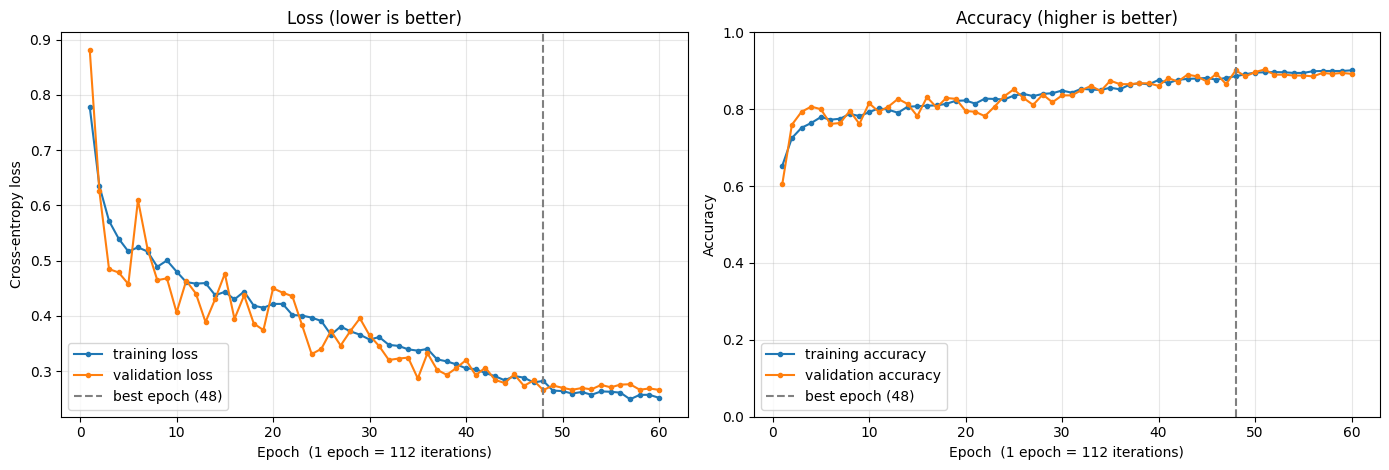

Best epoch 48 (after 5376 iterations):
  training loss   0.282   training accuracy   88.6%
  validation loss 0.266   validation accuracy 90.1%


In [71]:
epochs = history["epoch"]
iterations_per_epoch = len(train_loader)  # 50 weight updates per epoch

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# --- Left: loss ---
ax = axes[0]
ax.plot(epochs, history["train_loss"], marker="o", markersize=3, label="training loss")
ax.plot(epochs, history["val_loss"], marker="o", markersize=3, label="validation loss")
ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
ax.set_title("Loss (lower is better)")
ax.set_xlabel(f"Epoch  (1 epoch = {iterations_per_epoch} iterations)")
ax.set_ylabel("Cross-entropy loss")
ax.legend()
ax.grid(alpha=0.3)

# --- Right: accuracy ---
ax = axes[1]
ax.plot(epochs, history["train_acc"], marker="o", markersize=3, label="training accuracy")
ax.plot(epochs, history["val_acc"], marker="o", markersize=3, label="validation accuracy")
ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
ax.set_title("Accuracy (higher is better)")
ax.set_xlabel(f"Epoch  (1 epoch = {iterations_per_epoch} iterations)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Save the figure in this run's folder (next to its model), so every run keeps its own graph
curves_path = os.path.join(run_dir, "training_vs_validation_loss_and_accuracy.png")
fig.savefig(curves_path, dpi=150, bbox_inches="tight")
print("Saved the graph to", curves_path)

plt.show()

# The numbers at the best epoch (= the saved model)
i = epochs.index(best_epoch)
print(f"Best epoch {best_epoch} (after {best_epoch * iterations_per_epoch} iterations):")
print(f"  training loss   {history['train_loss'][i]:.3f}   training accuracy   {history['train_acc'][i]:.1%}")
print(f"  validation loss {history['val_loss'][i]:.3f}   validation accuracy {history['val_acc'][i]:.1%}")

### 8.8 Summary checklist

If everything worked, you saw:

- [ ] 8.2: the run folder, and whether it will train or load
- [ ] 8.5: `PASSED` (close to 100% on the 96 memorized images)
- [ ] 8.6: one line per epoch, losses going down, `best` marks, then `Done` with the best epoch
      (or `Already trained - loaded` when running the notebook again)
- [ ] 8.7: the training and validation loss curves; the dashed line at the best epoch

**What comes next:** `model` now holds the **best** weights. The next section scores it **once** on the
test images (confusion matrix, per-class scores, misclassified images).